# Lighting and Blur Robustness
How does test-image darkening or Gaussian blur affect one-shot AnomalyDINO? This pilot covers MVTec AD bottle, seed 0. Each condition uses the same normal reference and 83 test images. Run from the thesis repository or its notebooks directory after inference.

In [1]:
from pathlib import Path
import json
import pandas as pd
from sklearn.metrics import roc_auc_score
from IPython.display import Image, display

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
study = root / 'results' / 'lighting_blur'
conditions = ['original', 'brightness_085', 'brightness_070', 'blur_075', 'blur_150']
def run_dir(condition):
    return study / condition / 'bottle_1shot_seed0'

## Matched image-level results
Read archived predictions and verify image IDs, labels, reference, map count, and recorded AUROC. Differences are percentage points relative to the original images.

In [2]:
scores = {}
rows = []
for condition in conditions:
    folder = run_dir(condition)
    record = json.loads((folder / 'run_complete.json').read_text())
    assert record['condition'] == condition and record['status'] == 'INFERENCE_COMPLETED'
    assert record['reference'] == 'bottle/train/good/000.png'
    assert record['category'] == 'bottle' and record['seed'] == 0
    table = pd.read_csv(folder / 'predictions.csv', float_precision='round_trip')
    table = table.set_index(['image', 'label'], verify_integrity=True).sort_index()
    labels = table.index.get_level_values('label')
    assert labels.value_counts().to_dict() == {1: 63, 0: 20}
    maps = folder / 'anomaly_maps/seed=0/bottle/test'
    map_ids = {p.relative_to(maps).with_suffix('.png').as_posix() for p in maps.glob('*/*.npy')}
    assert map_ids == set(table.index.get_level_values('image'))
    scores[condition] = table['anomaly_score']
    assert table.index.equals(scores['original'].index)
    auc = roc_auc_score(labels, scores[condition])
    assert abs(auc - record['image_auroc']) < 1e-10
    rows.append({'condition': condition, 'image_auroc': auc})

summary = pd.DataFrame(rows).set_index('condition')
summary['change_pp'] = 100 * (summary.image_auroc - summary.loc['original', 'image_auroc'])
display(summary)

,image_auroc,change_pp
condition,,
original,0.998413,0.00000
brightness_085,0.998413,0.00000
brightness_070,0.998413,0.00000
blur_075,0.998413,0.00000
blur_150,0.993651,-0.47619


## Changes in individual scores
A stable AUROC can coexist with changes in individual predictions. Compare signed and absolute changes within each ground-truth group.

In [3]:
changes = pd.DataFrame(scores).subtract(scores['original'], axis='index').drop(columns='original')
display(changes.groupby(level='label').mean().rename(index={0:'Normal', 1:'Anomalous'}))
display(changes.abs().groupby(level='label').mean().rename(index={0:'Normal', 1:'Anomalous'}))

,brightness_085,brightness_070,blur_075,blur_150
label,,,,
Normal,0.000146,0.000920,-0.003860,0.013204
Anomalous,0.000297,-0.000484,-0.001082,-0.006376


,brightness_085,brightness_070,blur_075,blur_150
label,,,,
Normal,0.002165,0.002967,0.007572,0.019030
Anomalous,0.002815,0.005098,0.009800,0.022289


## A normal bottle under blur
The archived comparison uses one color scale for the two patch maps. Inspect the lower-right rim of good/001.png. This is a qualitative inspection of a normal sample.

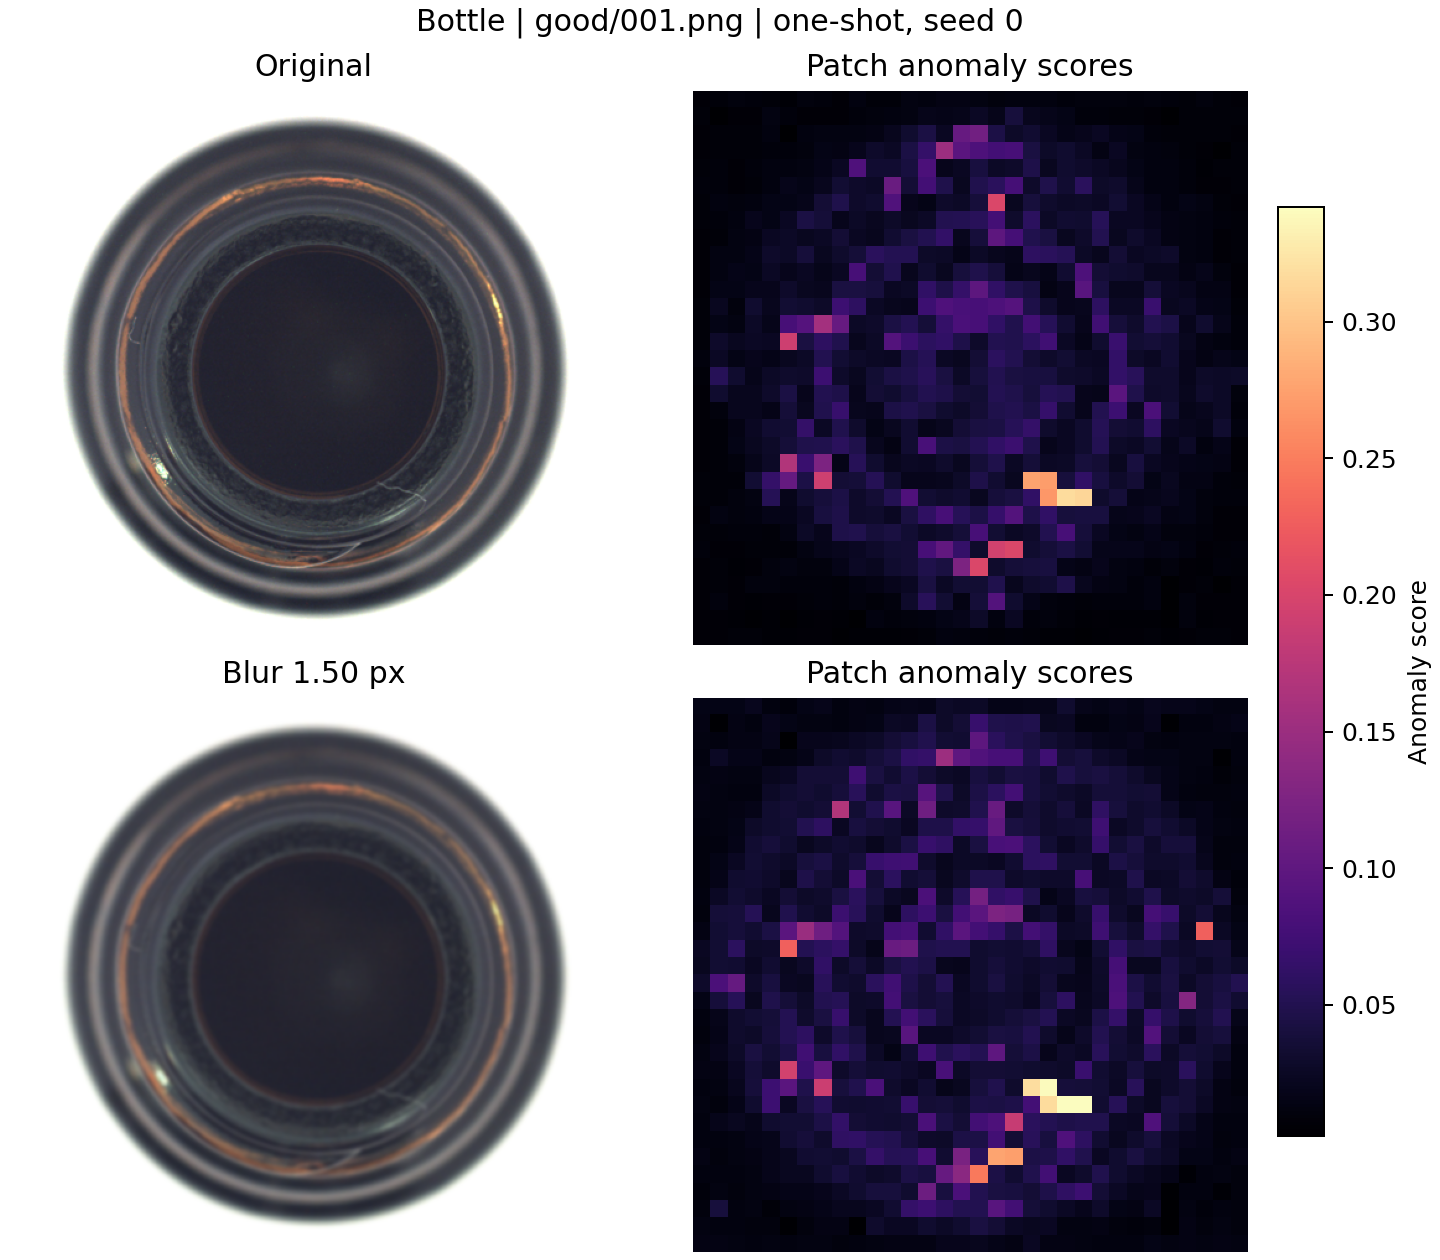

In [4]:
figure = study / 'figures/bottle_good_001_original_vs_blur150.png'
display(Image(filename=str(figure)))

## Pixel localization
Pending evaluation of the five conditions against original-resolution ground truth. Use the baseline reconstruction and evaluation settings, including an AUPRO integration limit of 0.30. Verify the original condition against the archived baseline before interpreting perturbations.